# Análise exploratória: dataset Steam

Objetivo: entender o volume, a esparsidade e a distribuição das interações antes de escolher os modelos. Os dados vêm de `data/raw/steam/` (rode `scripts/download_data.sh` antes) e a limpeza é a mesma de `recsys/data.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recsys import data
from recsys.data import build_matrix, confidence_score, load_dataset

RAW = ROOT / data.DEFAULT_DATA_DIR
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b8b7b2",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.axisbelow": True,
    }
)

## 1. Arquivos brutos e duplicados

In [2]:
purchases_raw = pd.read_csv(RAW / data.PURCHASE_FILE, sep="\t")
plays_raw = pd.read_csv(RAW / data.PLAY_FILE, sep="\t")
games_raw = pd.read_csv(RAW / data.GAMES_FILE, sep="\t")

pair = ["User_ID", "Game_ID"]
pd.DataFrame(
    {
        "linhas": [len(purchases_raw), len(plays_raw), len(games_raw)],
        "usuários": [purchases_raw.User_ID.nunique(), plays_raw.User_ID.nunique(), None],
        "jogos": [purchases_raw.Game_ID.nunique(), plays_raw.Game_ID.nunique(), len(games_raw)],
        "pares duplicados": [
            purchases_raw.duplicated(pair).sum(),
            plays_raw.duplicated(pair).sum(),
            None,
        ],
    },
    index=["compras", "horas", "catálogo"],
).astype("Int64")

,linhas,usuários,jogos,pares duplicados
compras,129511,12393,5155,707
horas,70489,11350,3600,12
catálogo,5155,<NA>,5155,<NA>


- As 707 compras duplicadas são linhas idênticas: basta removê-las.
- Os 12 pares repetidos em horas são sessões separadas do mesmo jogo: as horas são somadas.
- Toda linha de horas tem compra correspondente.
- Dois jogos repetem o nome de outro com um espaço no fim (abaixo). A limpeza unifica cada par no menor ID, então o catálogo limpo tem 5.153 jogos.

In [3]:
stripped = games_raw["Game Name"].str.strip()
games_raw[stripped.duplicated(keep=False)].assign(nome_bruto=lambda d: d["Game Name"].map(repr))[
    ["Game_ID", "nome_bruto"]
]

,Game_ID,nome_bruto
638,639,'Universe Sandbox'
857,858,'Duke Nukem Forever'
3255,3256,'Universe Sandbox '
4500,4501,'Duke Nukem Forever '


## 2. Visão geral dos dados limpos

In [4]:
ds = load_dataset(RAW)
inter = ds.interactions
m = build_matrix(inter)
per_user = inter.groupby("user_id").size()
per_game = inter.groupby("game_id").user_id.nunique()
played = inter.loc[inter.hours > 0, "hours"]

resumo = {
    "interações (pares usuário–jogo)": f"{len(inter):,}",
    "usuários": f"{inter.user_id.nunique():,}",
    "jogos com interação / catálogo": f"{inter.game_id.nunique():,} / {len(ds.games):,}",
    "esparsidade da matriz": f"{m.sparsity:.2%}",
    "usuários com 1 jogo": f"{(per_user == 1).mean():.1%}",
    "mediana de jogos por usuário": f"{per_user.median():.0f}",
    "usuários com ≥ 5 jogos": f"{(per_user >= 5).mean():.1%} ({(per_user >= 5).sum():,})",
    "jogos com um único usuário": f"{(per_game == 1).mean():.1%}",
    "compras sem horas jogadas": f"{(inter.hours == 0).mean():.1%}",
    "horas (mediana · p90 · p99 · máx.)": " · ".join(
        f"{v:,.1f}" for v in played.quantile([0.5, 0.9, 0.99, 1.0])
    ),
}
pd.Series(resumo, name="valor").to_frame()

,valor
interações (pares usuário–jogo),"128,801"
usuários,"12,393"
jogos com interação / catálogo,"5,153 / 5,153"
esparsidade da matriz,99.80%
usuários com 1 jogo,46.0%
mediana de jogos por usuário,2
usuários com ≥ 5 jogos,"30.3% (3,757)"
jogos com um único usuário,22.7%
compras sem horas jogadas,45.3%
horas (mediana · p90 · p99 · máx.),"4.5 · 76.0 · 908.0 · 11,754.0"


## 3. Horas jogadas

Cauda muito longa: por isso o score usa `log1p(horas)`.

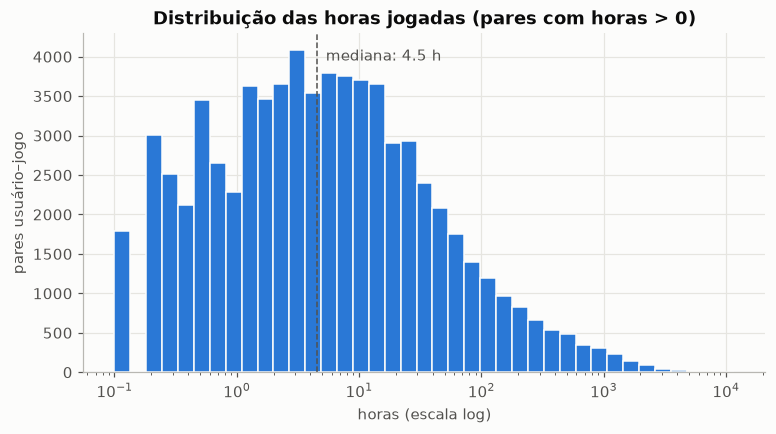

In [5]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(played.min()), np.log10(played.max()), 40)
ax.hist(played, bins=bins, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log")
ax.axvline(played.median(), color="#52514e", linestyle="--", linewidth=1)
ax.annotate(
    f"mediana: {played.median():.1f} h",
    (played.median(), ax.get_ylim()[1] * 0.92),
    xytext=(6, 0),
    textcoords="offset points",
    color="#52514e",
)
ax.set(
    title="Distribuição das horas jogadas (pares com horas > 0)",
    xlabel="horas (escala log)",
    ylabel="pares usuário–jogo",
)
plt.show()

## 4. Jogos por usuário

Quase metade dos usuários tem um único jogo: cold start pesado.

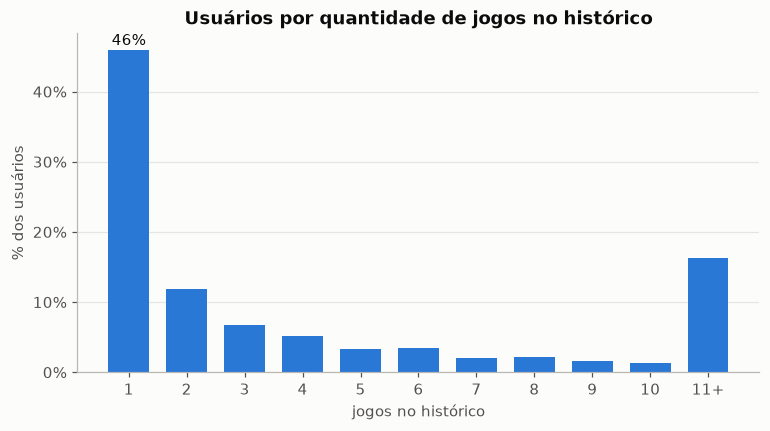

In [6]:
buckets = per_user.clip(upper=11).value_counts().sort_index()
labels = [str(i) for i in buckets.index[:-1]] + ["11+"]
fig, ax = plt.subplots()
bars = ax.bar(labels, buckets.values / len(per_user), color=BLUE, width=0.7)
first = buckets.iloc[0] / len(per_user)
ax.annotate(
    f"{first:.0%}",
    (0, first),
    xytext=(0, 3),
    textcoords="offset points",
    ha="center",
    color="#0b0b0b",
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.set(
    title="Usuários por quantidade de jogos no histórico",
    xlabel="jogos no histórico",
    ylabel="% dos usuários",
)
plt.show()

## 5. Jogos mais populares

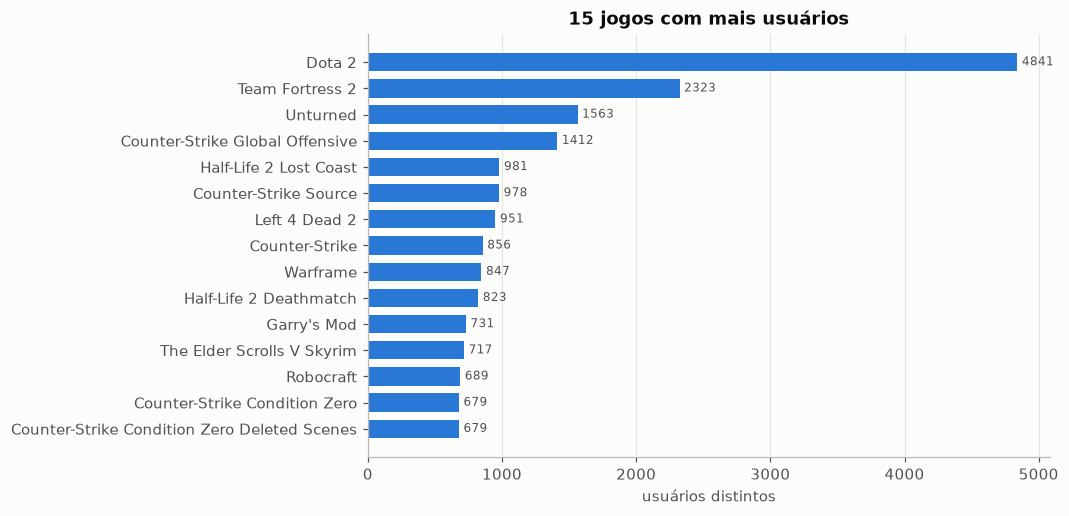

In [7]:
top = (
    per_game.sort_values(ascending=False)
    .head(15)
    .rename("usuários")
    .to_frame()
    .join(ds.games.set_index("game_id")["name"])
)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top["name"][::-1], top["usuários"][::-1], color=BLUE, height=0.7)
ax.bar_label(bars, padding=3, color="#52514e", fontsize=8)
ax.grid(axis="y", visible=False)
ax.set(title="15 jogos com mais usuários", xlabel="usuários distintos")
plt.show()

## 6. Concentração da popularidade (cauda longa)

Uma fração pequena do catálogo concentra a maior parte das interações. Um recomendador só por popularidade vai cobrir pouco do catálogo; a avaliação deve medir cobertura e novidade, não só acurácia.

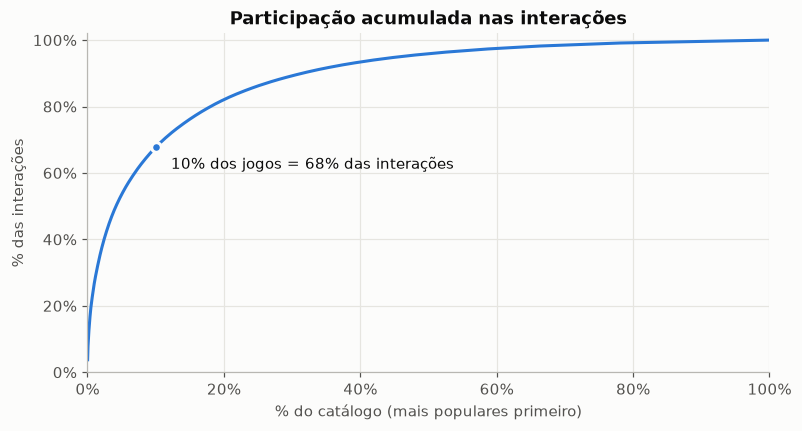

In [8]:
counts = inter.groupby("game_id").size().sort_values(ascending=False).to_numpy()
share = counts.cumsum() / counts.sum()
frac = np.arange(1, len(counts) + 1) / len(counts)
top10 = share[int(len(counts) * 0.10) - 1]
fig, ax = plt.subplots()
ax.plot(frac, share, color=BLUE, linewidth=2)
ax.scatter([0.10], [top10], color=BLUE, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.annotate(
    f"10% dos jogos = {top10:.0%} das interações",
    (0.10, top10),
    xytext=(10, -14),
    textcoords="offset points",
    color="#0b0b0b",
)
pct = plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set(
    title="Participação acumulada nas interações",
    xlabel="% do catálogo (mais populares primeiro)",
    ylabel="% das interações",
    ylim=(0, 1.02),
    xlim=(0, 1),
)
plt.show()

## 7. Score de confiança

`score = 1 + α · log1p(horas)`. Comprar sem jogar vale 1; jogar muito aumenta o score de forma logarítmica. O α será escolhido na avaliação (0,5 / 1 / 2).

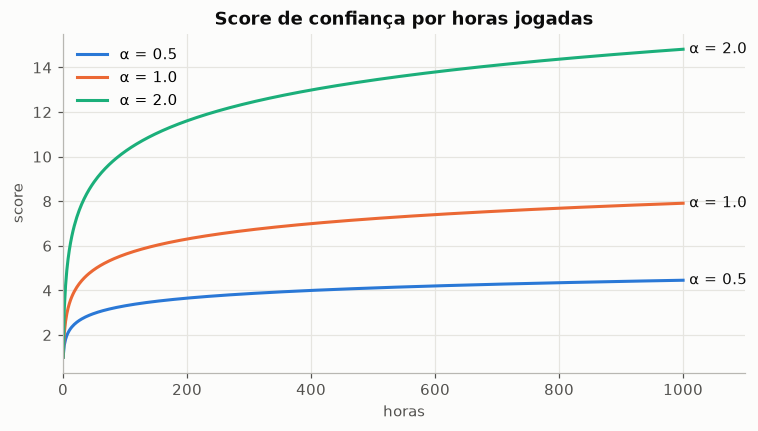

,count,mean,std,min,25%,50%,75%,max
score (α = 1),128801.0,2.12,1.57,1.0,1.0,1.26,2.9,10.37


In [9]:
hours = np.linspace(0, 1000, 500)
fig, ax = plt.subplots()
for alpha, color in [(0.5, BLUE), (1.0, ORANGE), (2.0, AQUA)]:
    y = confidence_score(hours, alpha)
    ax.plot(hours, y, color=color, linewidth=2, label=f"α = {alpha}")
    ax.annotate(
        f"α = {alpha}",
        (hours[-1], y[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        color="#0b0b0b",
    )
ax.legend(frameon=False, loc="upper left")
ax.set(title="Score de confiança por horas jogadas", xlabel="horas", ylabel="score", xlim=(0, 1100))
plt.show()

inter["score"].describe().round(2).to_frame("score (α = 1)").T

## 8. Conclusões para o projeto

1. **Feedback implícito**: não há notas; compra + horas viram o score de confiança.
2. **Esparsidade de 99,8%**: a matriz precisa ser esparsa (`scipy.sparse`) e o item-kNN deve guardar só os top-k vizinhos.
3. **Cold start**: quase metade dos usuários tem 1 jogo; popularidade e conteúdo são parte central do híbrido.
4. **Avaliação**: usar usuários com ≥ 5 jogos (cerca de 30%) para o protocolo 80/20.
5. **Cauda longa**: medir cobertura e novidade, além de Precision/Recall/NDCG.